# RelativisticDynamics.jl demo

This notebook demonstrates how to use the `RelativisticDynamics.jl` package

In [2]:
using Revise
using RelativisticDynamics

---

## 1. Example Orbital Trajectory

The core aim of `RelativisticDynamics.jl` is to be able to accurately describe the spin-orbital evolution of a relativistic system. This can be easily done using the default settings as:

In [6]:
solution,model,message  = orbit();

In [7]:
message 

"Hey now this is a test to see if changes are reflected in the main file"

We can use `Plots.jl` in conjunction with the inbuilt `RelativisticDynamics.jl` plotting recipe to plot e.g. the orbital trajectory:

In [9]:
import Pkg; Pkg.add("Plots")

    Updating registry at `~/.julia/registries/General.toml`
   Resolving package versions...
   Installed GR_jll ──────────────────── v0.73.12+0
   Installed JpegTurbo_jll ───────────── v3.1.1+0
   Installed Xorg_xkbcomp_jll ────────── v1.4.6+1
   Installed Unitful ─────────────────── v1.22.0
   Installed PlotUtils ───────────────── v1.4.3
   Installed LERC_jll ────────────────── v4.0.1+0
   Installed Libmount_jll ────────────── v2.40.3+0
   Installed Xorg_libxkbfile_jll ─────── v1.1.2+1
   Installed EpollShim_jll ───────────── v0.0.20230411+1
   Installed Xorg_libXinerama_jll ────── v1.1.5+0
   Installed GR ──────────────────────── v0.73.12
   Installed Bzip2_jll ───────────────── v1.0.8+4
   Installed ColorSchemes ────────────── v3.28.0
   Installed Xorg_libpthread_stubs_jll ─ v0.1.2+0
   Installed Libgpg_error_jll ────────── v1.51.1+0
   Installed Fontconfig_jll ──────────── v2.15.0+0
   Installed xkbcommon_jll ───────────── v1.4.1+2
   Installed Pango_jll ───────────────── v1.55.5+

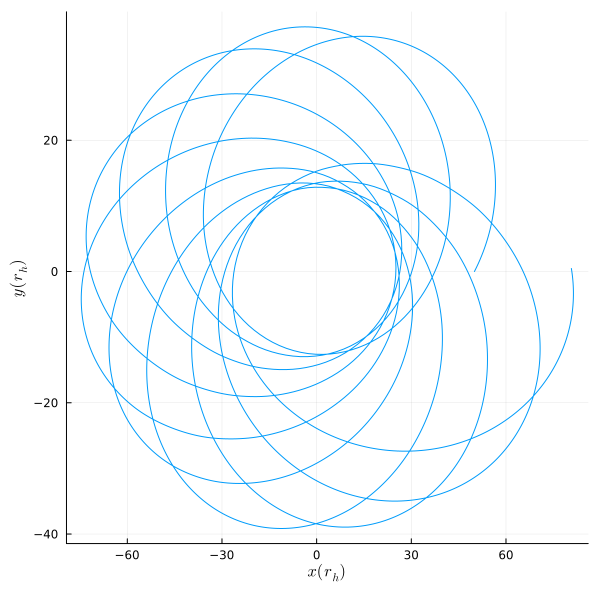

In [10]:
using Plots 
plot(solution,model.constants.a)

---

## 2. Flexible number format

How do the solutions compare using different number formats?

In [11]:
solutionF64,modelF64 = orbit(NF=Float64);
solutionF32,modelF32 = orbit(NF=Float32);

See also Posits, Stochastic rounding, DoubleFloats.jl, ArbNumerics.jl e.g. https://tutorials.sciml.ai/html/type_handling/01-number_types.html



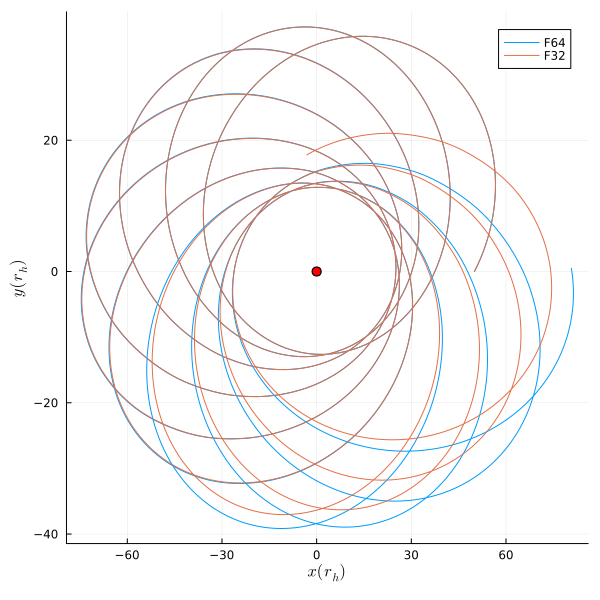

In [12]:
plt = plot(solutionF64,modelF64.constants.a,label="F64")
plt = plot!(solutionF32,modelF32.constants.a,linecolor=2,label="F32",legend=true)
plt = scatter!(0:0, 0:0,markercolor="red",markersize=5,label="")

# 3. Stochastic rounding 

In [13]:
julia>] add StochasticRounding

Base.Meta.ParseError: ParseError:
# Error @ /Users/tomkimpson/projects/RelativisticDynamics.jl/notebooks/jl_notebook_cell_df34fa98e69747e1a8f8a730347b8e2f_X33sZmlsZQ==.jl:1:7
julia>] add StochasticRounding
#     ╙ ── unexpected `]`

In [14]:
using Pkg 

In [15]:
Pkg.add("StochasticRounding")

   Resolving package versions...
   Installed Polynomials ────────── v4.0.13
   Installed BFloat16s ──────────── v0.5.0
   Installed StochasticRounding ─── v0.8.2
   Installed Quadmath ───────────── v0.5.10
   Installed GenericLinearAlgebra ─ v0.3.15
   Installed DoubleFloats ───────── v1.4.2
      Compat entries added for StochasticRounding
    Updating `~/projects/RelativisticDynamics.jl/Project.toml`
  [3843c9a1] + StochasticRounding v0.8.2
    Updating `~/projects/RelativisticDynamics.jl/Manifest.toml`
  [ab4f0b2a] + BFloat16s v0.5.0
  [497a8b3b] + DoubleFloats v1.4.2
  [14197337] + GenericLinearAlgebra v0.3.15
  [f27b6e38] + Polynomials v4.0.13
  [be4d8f0f] + Quadmath v0.5.10
  [3843c9a1] + StochasticRounding v0.8.2
Precompiling project...
    758.0 ms  ✓ BFloat16s
    756.5 ms  ✓ Quadmath
    894.1 ms  ✓ GenericLinearAlgebra
    650.7 ms  ✓ LLVM → BFloat16sExt
   1524.1 ms  ✓ Enzyme → EnzymeBFloat16sExt
   9249.7 ms  ✓ Polynomials
    889.0 ms  ✓ Polynomials → PolynomialsChainRul

In [17]:
using StochasticRounding

In [20]:
a = Float32sr(200.0)

200.0f0

In [101]:

α=20
e = 0.5
Norbits=10

solutionF64,modelF64 = orbit(NF=Float64,α=α,e=e,Norbits=Norbits);
solutionF32,modelF32 = orbit(NF=Float32,α=α,e=e,Norbits=Norbits);
solutionF32SR,modelF32SR = orbit(NF=Float32sr,α=α,e=e,Norbits=Norbits);



In [108]:
solutionF64,modelF64 = orbit(NF=Float64);
solutionF32,modelF32 = orbit(NF=Float32);
solutionF32SR,modelF32SR = orbit(NF=Float32sr);


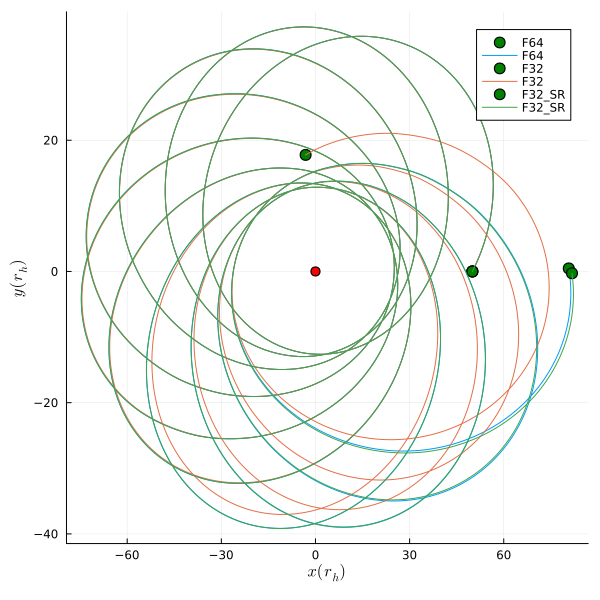

In [109]:
plt = plot(solutionF64,modelF64.constants.a,label="F64",legend=true)
plt = plot!(solutionF32,modelF32.constants.a,linecolor=2,label="F32",legend=true)
plt = plot!(solutionF32SR,modelF32SR.constants.a,linecolor=3,label="F32_SR",legend=true)


#Plot the BH at the origin
plt = scatter!(0:0, 0:0,markercolor="red",markersize=5,label="")



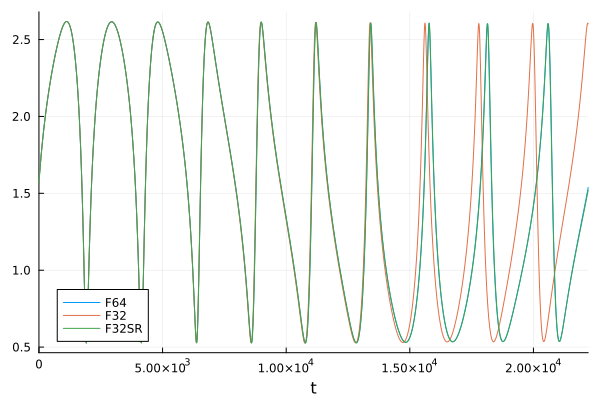

In [110]:


tspan = nothing 
plot(solutionF64,idxs = [(0, 3)],label="F64",legend=true,tspan = tspan)
plot!(solutionF32,idxs = [(0, 3)],label="F32",legend=true,tspan = tspan)
plot!(solutionF32SR,idxs = [(0, 3)],label="F32SR",legend=true,tspan = tspan)

In [61]:
solutionF64.u[1,:]

1-element Vector{Vector{Float64}}:
 [0.0, 100.0, 1.5707963267948966, 0.0, 3.553706169878906e-7, 3.4459869641945677e-9, 3.062343986178921e-10, 1.768753204649369e-10, -3.532188105405291e-15, 2.4838592692165083e-14, -4.3021704531338955e-16, 0.0]

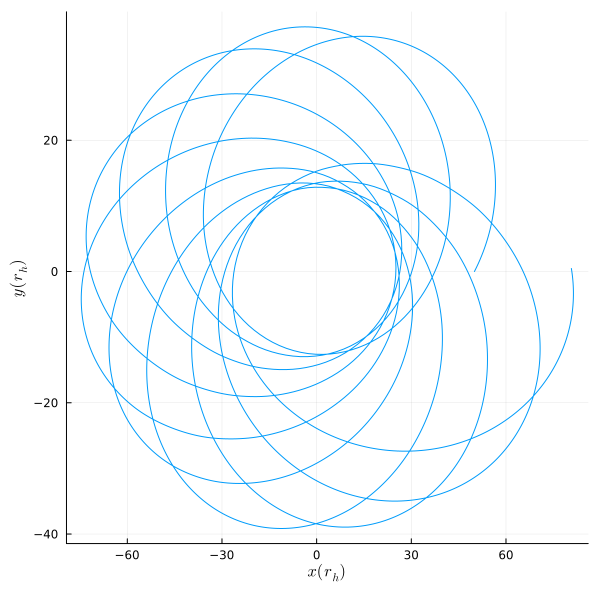

In [28]:
plot_object = plot(solutionF64,modelF64.constants.a,label="F64")

In [47]:
last(solutionF64)

12-element Vector{Float64}:
 22896.826535365733
    80.76417967529052
     1.5381952029397687
    62.83757237709227
     3.553941687695585e-7
    -5.671859233872788e-9
     2.9984600297803396e-10
     1.7853240095185895e-10
     3.448201817672547e-15
     8.243536411520345e-16
     3.4325121719804114e-16
     4.949909039792484e-16

In [48]:
first(solutionF64)

12-element Vector{Float64}:
  0.0
 50.0
  1.5707963267948966
  0.0
  3.6099649378298974e-7
  2.3936235343199422e-8
  7.763224048232442e-10
  4.4878460714554864e-10
 -3.0315904846625962e-15
  2.4838592692165083e-14
 -8.604340906267791e-16
  0.0

In [32]:
#Up-sample the solution according to the upsample factor 

sol = solutionF64
upsample=10
T = range(first(sol.t),last(sol.t),length=length(sol.t)*upsample)
p = sol(T);

# Extract relevant data from the interpolated solution 
r = p[2,:];
θ = p[3,:] ;
ϕ = p[4,:];

# Boyer lindquist to Cartesian 
w = sqrt.(r.^2 .+ a^2) ;
x = w .* sin.(θ) .* cos.(ϕ);
y = w .* sin.(θ) .* sin.(ϕ);
z = r .* cos.(θ);

In [34]:
x[1]

206.15528128088303

In [35]:
y[1]

0.0

In [37]:
x[end]

215.57343075525867

In [38]:
y[end]

1.2329437076949399